# AI-generated reference solution, NOT part of our submission

This notebook was produced by an AI coding agent (Claude Code) on 30.10.2026, between 11:14 and 11:54, in a separate environment without access to our notebook. Dominic ran it as a test of his own agent setup and shares it as a second opinion for the group; none of us wrote or edited its analysis cells. Our own notebook and app were also built with an AI assistant, with our guesses and decisions; this file is an independent second AI run on the same task. Our submission is `01_flower_classification_project_dominic.ipynb`, `app.py` and `models/step5_finetuned.keras`.

- **Same task, same photos:** the current version of the task (seven steps, `data/train`, `data/validation`, `data/test`), 160 × 160, MobileNetV2 with a dense head, with and without augmentation, no fine-tuning. Its result: 26 of 30 test photos (86.7 %); ours: 29 of 30.
- **Its own brief:** besides the course task the agent followed a written brief and its own method checklist. Some rules in its text come from there, not from the course: at most 160 × 160 pixels, a 45-minute limit, step 7 checked in code without starting the app, the file `ergebnis.json` (German keys), the word "TESTZUGRIFF" and the "notes for the client".
- **Some decisions differ from ours:** it chose the head by cross-validation on the training photos; it kept the model without augmentation (validation 0.833) over the one with augmentation (0.850) by a stricter rule of its own instead of "choose by validation accuracy"; and it set its staff threshold at 0.95, because no threshold reached its own target of 95 % correct answers.
- **Running it:** its paths are relative to the working directory (`data/`, `models/`, `abgabe/`), so it only runs from the repository root, for example as a copy there. Opened in `reference/`, it stops at the first data cell after creating empty folders. Run from the root, it adds `dense_head.keras`, `dense_head_aug.keras` and `seed_repeats/` to `models/` (they then appear in our app's model list; our model is not overwritten) and writes `abgabe/` (do not commit it). It took about 11 minutes on the Linux laptop it was made on; the first run also downloads the MobileNetV2 weights.
- **Changed against the original:** this cell added; the closing table that checked the notebook against the agent's method checklist removed; editor metadata replaced by a kernel entry. Cells 1 onward, with all outputs, are unchanged.

Do not copy code or decisions from here into the submission without understanding and re-deriving them. We opened it only after our own model choice and our single test evaluation. An earlier reference for the old version of the task was in this repository for about 45 minutes on 30.10. and was removed again; it is still in the Git history.

# Flower Classification with Transfer Learning: a Reference Solution

**Question.** A garden centre wants to know which of three flowers (rose, sunflower, tulip) a customer photo shows.
We have only **100 training photos per flower**. We answer three questions:

1. How good is a pretrained network (**MobileNetV2, frozen**) with a small **dense head**?
2. What does **data augmentation** add?
3. **Which photos does the chosen model get wrong**, so that staff know when to check its answer?

**What one row is.** One example is **one photo**. The model is used at the moment a customer uploads a photo;
it sees only the pixels, nothing else. The independent unit is the photo: 300 for training, 60 for validation,
30 for the test. (Some photos may show the same flower twice; we check this in step 1.)

**How we work.** We follow the seven steps of the course task in their order. Before every code cell, a short text says
**what** the cell does, **which decision** it makes, **why**, and which **alternative** we rejected.
After every output, a cell **"What we see"** puts the numbers into words.

The diagram of the seven steps is in the course repository: `assets/flowers_project_workflow.png`.

## 0. Setup

**What:** import the libraries of the course, fix all random seeds and print the package versions.

**Decision:** we call `keras.utils.set_random_seed(42)` and, in addition,
`tf.config.experimental.enable_op_determinism()`. This second call is **not part of the course**: it tells TensorFlow to
use only operations that give the same result every time, also when the CPU works with several threads.

**Why:** with only 60 validation photos, one photo changes the accuracy by 1.7 percentage points. If two runs of the same
notebook gave different numbers, we could not tell a real difference from noise.

**Alternative rejected:** seeds only. Then the order of additions on several CPU threads can still change the last digits
of the weights, and sometimes the prediction for a borderline photo.

We also hide TensorFlow's start-up messages about the CPU (`TF_CPP_MIN_LOG_LEVEL`) and one Keras warning that
`fit` ignores `shuffle=True` for a dataset (our dataset already shuffles itself). Both are only messages; they change
nothing in the computation.

**What stays random even so:** the seed itself. Another seed gives other initial weights of the head, another order of the
training photos, other dropout masks and other augmented images. We measure this effect in step 5 by training every
model with three seeds.

In [1]:
import hashlib
import json
import os
import warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow's info messages; must be set before the import
warnings.filterwarnings("ignore", message=".*shuffle=True.*")

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from keras import layers
from keras.applications import mobilenet_v2
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold

SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

DATA = Path("data")
MODELS = Path("models")
OUT = Path("abgabe")  # files for the hand-in: error photos and ergebnis.json
MODELS.mkdir(exist_ok=True)
(OUT / "fehler").mkdir(parents=True, exist_ok=True)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| scikit-learn", sklearn.__version__,
      "| NumPy", np.__version__, "| pandas", pd.__version__)

I0000 00:00:1793356802.883889 1016036 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793356802.885151 1016036 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793356805.703643 1016036 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793356805.707959 1016036 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | Keras 3.15.1 | scikit-learn 1.9.1 | NumPy 2.5.4 | pandas 3.1.0


**What we see:** the versions of the course environment (TensorFlow 2.21, Keras 3.15, scikit-learn 1.9).
Anyone who runs this notebook with these versions and the same photos should get the same numbers.

## Fixed before the first model: metric, success criterion and selection rule

We write these rules down **before** we train any model, so that the results cannot change them.

| Item | Our choice | Alternative we rejected, and why |
|---|---|---|
| **Main metric** | **Accuracy** (share of correct photos). The course asks for it, and the three classes have the same size (100 / 20 / 10 each), so accuracy is not distorted by a large class. | Macro F1: with balanced classes it says almost the same and is harder to explain to the garden centre. |
| **Second metric** (only to tune the head and break ties) | **Cross-entropy loss** on the validation photos. It uses the probabilities, so it changes smoothly, while accuracy jumps in steps of 1.7 points. | Accuracy alone: too coarse for 60 photos. |
| **Baseline** | **Random guessing** (each class with probability 1/3, seed fixed). Expected accuracy 33.3 %. With balanced classes "always say rose" also gets 33.3 %. | No baseline: then we could not show that the model learned anything. |
| **Success criterion** | The chosen model reaches **at least 80 % validation accuracy**, and the **paired 95 % interval** of its advantage over random guessing lies **fully above 0**. The garden centre gave no number; 80 % means that staff would only need to look at a small part of the photos. Random guessing and every constant answer (33.3 %) fail this criterion. | A higher bar like 95 %: with 60 photos we could not show it reliably. |
| **Selection rule** (step 5) | The augmented model **replaces** the simpler model without augmentation **only if** (a) its paired 95 % bootstrap interval of the accuracy difference on the 60 validation photos lies fully above 0, **and** (b) its mean validation accuracy over three seeds is also higher. Otherwise we keep the simpler model. | "Take the higher validation accuracy": a difference of one or two photos (1.7 or 3.3 points) is within the noise of 60 photos and of the seed, so this rule would often pick by chance. |
| **If no model meets the criterion** | We still report all models on the test set, but we say that the model should not be used without a staff check of every photo. | |

There is no figure for these rules: they are fixed **before** any result, so there is nothing to plot yet. The table in
step 1a shows the equal class sizes that make accuracy a fair metric.

**How we treat differences of 1.7 points (one photo).** We never decide on one photo. We compare two models
**paired**, photo by photo, on the same 60 validation photos (bootstrap, explained in step 5), and we look at the spread
over three seeds. A difference that is smaller than this noise is "no difference", and then the simpler model wins.

## Step 1. Get the data

### 1a. Check the folders and the files (structure only)

**What:** count the photos per folder and check that every file is a readable image. We read only the file headers with
Pillow (`PIL`, the image library that Keras uses underneath), not the pixels.

**Decision:** we check `train` and `validation` now. The folder `test` stays closed until step 6, as the course asks.
We only know from the data description that it holds 10 photos per class.

**Alternative rejected:** checking the test photos now as well. This would already be a look at the test set.

In [2]:
rows = []
for split in ["train", "validation"]:
    for path in sorted((DATA / split).glob("*/*")):
        with Image.open(path) as img:
            rows.append({"split": split, "label": path.parent.name, "file": path.name, "format": img.format,
                         "mode": img.mode, "width": img.width, "height": img.height,
                         "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
files = pd.DataFrame(rows)
pd.crosstab(files["label"], files["split"], margins=True)

split,train,validation,All
label,,,
rose,100,20,120
sunflower,100,20,120
tulip,100,20,120
All,300,60,360


In [3]:
print("File formats:", files["format"].value_counts().to_dict())
print("Colour modes:", files["mode"].value_counts().to_dict())
print("Width from", files["width"].min(), "to", files["width"].max(),
      "| height from", files["height"].min(), "to", files["height"].max())
print("Photos that appear twice (same bytes):", files["sha256"].duplicated().sum())

File formats: {'JPEG': 360}
Colour modes: {'RGB': 360}
Width from 159 to 640 | height from 180 to 407
Photos that appear twice (same bytes): 0


**What we see:** 100 photos per class for training and 20 per class for validation, as described.
All 360 files are JPEG in RGB colour mode, so no photo needs a colour conversion. The widths go from 159 to 640 pixels,
the heights from 180 to 407 pixels. No file appears twice with the same bytes (0 exact copies).

### 1b. Photo sizes: which `image_size`?

**What:** plot the shorter side of every photo, and show one photo at three possible sizes.

**Decision:** `image_size=(160, 160)` for every model.

**Why:** (1) the task allows at most 160 × 160; (2) Keras offers MobileNetV2 weights trained at 96, 128, 160, 192 and
224 pixels, so 160 is the largest size with matching weights; (3) the figure shows that small details (the centre of a
sunflower, the petals of a rose) are still visible at 160 but blur at 96.

**Alternative rejected:** 128 or 96 pixels. They train faster, but we lose detail, and training at 160 already takes only
a few seconds per epoch on a laptop CPU. We do **not** try all sizes on the validation set: this would cost much time and
add one more choice made on only 60 photos.

**Aspect ratio:** `image_dataset_from_directory` squeezes every photo to a square (it does not crop). The app `app.py` does
exactly the same with `tf.image.resize`. Cropping (`crop_to_aspect_ratio=True`) would cut away parts of the flower and
would need a change in the app, so we keep the default.

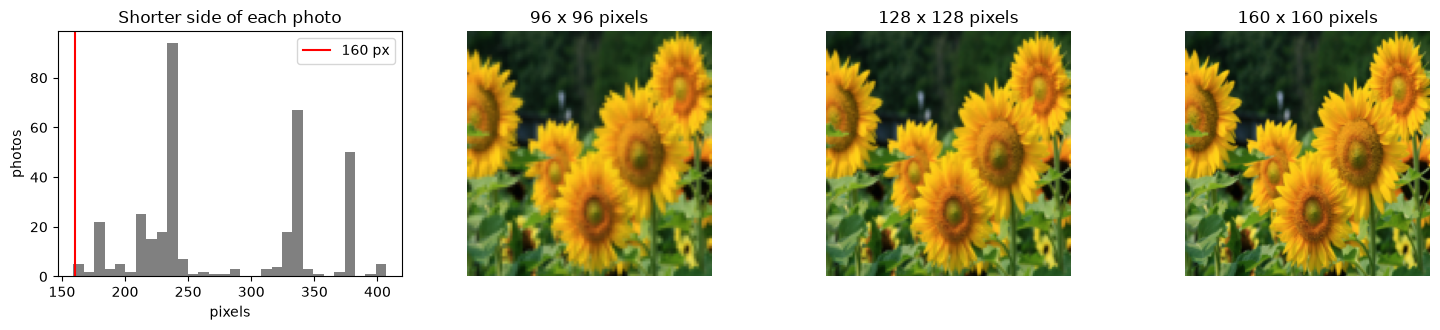

Photos with a shorter side below 160 px: 5 of 360


In [4]:
IMAGE_SIZE = (160, 160)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
axes[0].hist(files[["width", "height"]].min(axis=1), bins=30, color="grey")
axes[0].axvline(IMAGE_SIZE[0], color="red", label="160 px")
axes[0].set(title="Shorter side of each photo", xlabel="pixels", ylabel="photos")
axes[0].legend()
example = Image.open(DATA / "train" / "sunflower" / files.query("label == 'sunflower'")["file"].iloc[0])
for ax, size in zip(axes[1:], [96, 128, 160]):
    ax.imshow(example.resize((size, size), Image.BILINEAR))
    ax.set(title=f"{size} x {size} pixels")
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Photos with a shorter side below 160 px:", (files[["width", "height"]].min(axis=1) < 160).sum(), "of", len(files))

**What we see:** only 5 of 360 photos have a shorter side below 160 pixels; most have 240, 330 or 375 pixels. So at
160 × 160 we shrink almost every photo and enlarge almost none. At 96 pixels the petals and the centres of the sunflowers
are blurred; at 160 they are sharp. We keep `(160, 160)`.

### 1c. A few photos of every class

**What:** show four training photos per class, in their original size and shape.

**Decision:** we take the first four files of each folder (sorted by name), not a random choice, so that the figure is the
same in every run.

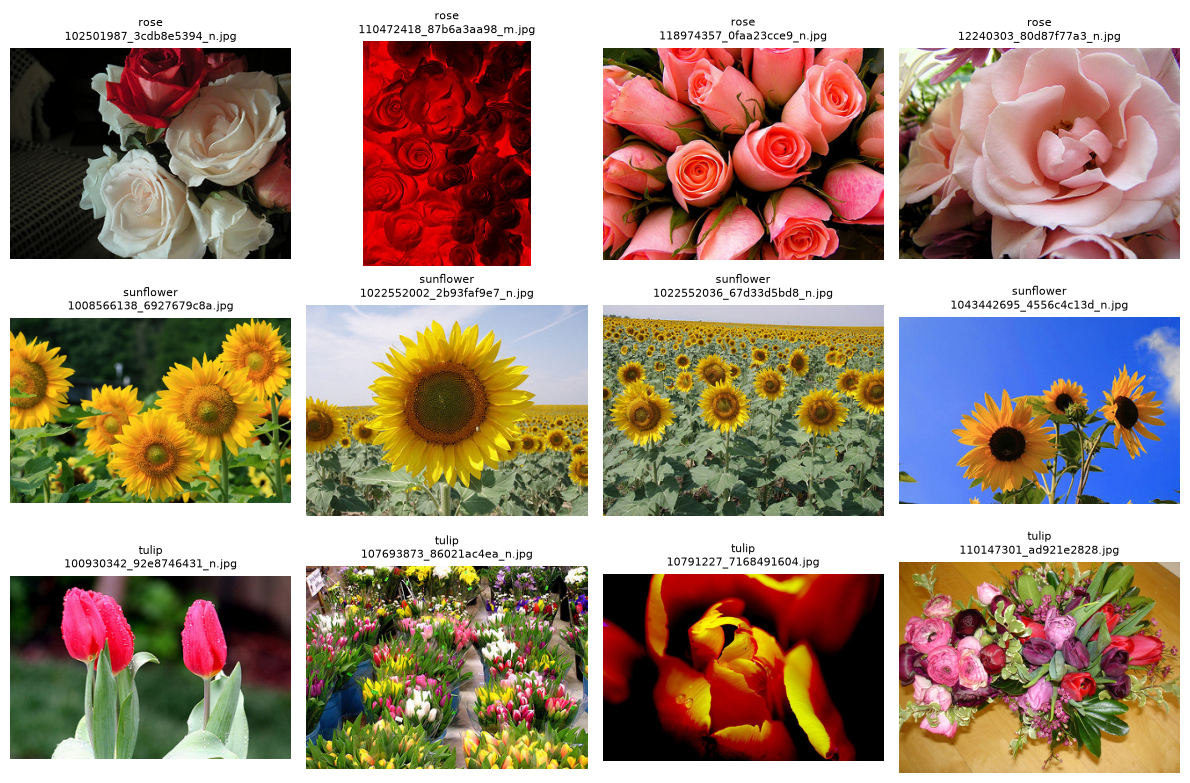

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for row, label in enumerate(["rose", "sunflower", "tulip"]):
    for col, name in enumerate(files.query("split == 'train' and label == @label")["file"].iloc[:4]):
        axes[row, col].imshow(Image.open(DATA / "train" / label / name))
        axes[row, col].set_title(f"{label}\n{name}", fontsize=8)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

**What we see:** the photos are very different: single flowers close up, fields, bunches, other objects in the background.
The shapes are not square, so the squeezing to 160 × 160 changes the proportions a little.

## Step 2. Load the training and the validation images

**What:** load `data/train` and `data/validation` with `keras.utils.image_dataset_from_directory`.

**Decisions:**
- `image_size=(160, 160)` for every dataset (step 1b).
- Training images: `shuffle=True` with `seed=42`, so the order changes every epoch but is the same in every run.
- Validation images: `shuffle=False`, so the order of predictions matches the order of the files.
- `batch_size=32` (Keras default). Alternative: larger batches; with 300 photos they would give only a few weight updates
  per epoch.
- `label_mode="int"` (default): labels 0, 1, 2 and the loss `sparse_categorical_crossentropy`. One-hot labels would work
  the same, but need a different loss.
- A second, **unshuffled** copy of the training set (`train_ordered`), used only to compute features and to find
  near-duplicates. The model is trained on the shuffled one.

**Pixels stay raw (0 to 255).** The preprocessing will be a layer inside the model, because `app.py` gives raw pixels.

In [6]:
train_ds = keras.utils.image_dataset_from_directory(DATA / "train", image_size=IMAGE_SIZE, batch_size=32,
                                                    shuffle=True, seed=SEED)
train_ordered = keras.utils.image_dataset_from_directory(DATA / "train", image_size=IMAGE_SIZE, batch_size=32,
                                                         shuffle=False)
val_ds = keras.utils.image_dataset_from_directory(DATA / "validation", image_size=IMAGE_SIZE, batch_size=32,
                                                  shuffle=False)
CLASSES = train_ds.class_names
assert CLASSES == val_ds.class_names == ["rose", "sunflower", "tulip"]  # same order as CLASSES in app.py
images, labels = next(iter(train_ds))
print("Classes:", CLASSES)
print("One batch:", images.shape, images.dtype, "| pixel range", float(images.numpy().min()), "to",
      float(images.numpy().max()))

Found 300 files belonging to 3 classes.


Found 300 files belonging to 3 classes.


Found 60 files belonging to 3 classes.


E0000 00:00:1793356812.619828 1016036 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.


Classes: ['rose', 'sunflower', 'tulip']
One batch: (32, 160, 160, 3) <dtype: 'float32'> | pixel range 0.0 to 255.0


**What we see:** Keras finds 300 training and 60 validation photos in 3 classes, in alphabetical order
rose, sunflower, tulip. This is the same order as `CLASSES` in `app.py`, so label 0 means rose everywhere.
A batch has the shape (32, 160, 160, 3) and the pixels go from 0 to 255: they are not yet scaled.

## Step 3. Explore the training set

### 3a. A grid of training photos with their labels

**What:** show 16 photos of one shuffled batch, as the model sees them (160 × 160, squeezed).

**Decision:** we show the images **and** labels from the same batch. Taking images from one loop and labels from another
loop over a shuffled dataset would mix them up, because each loop shuffles again.

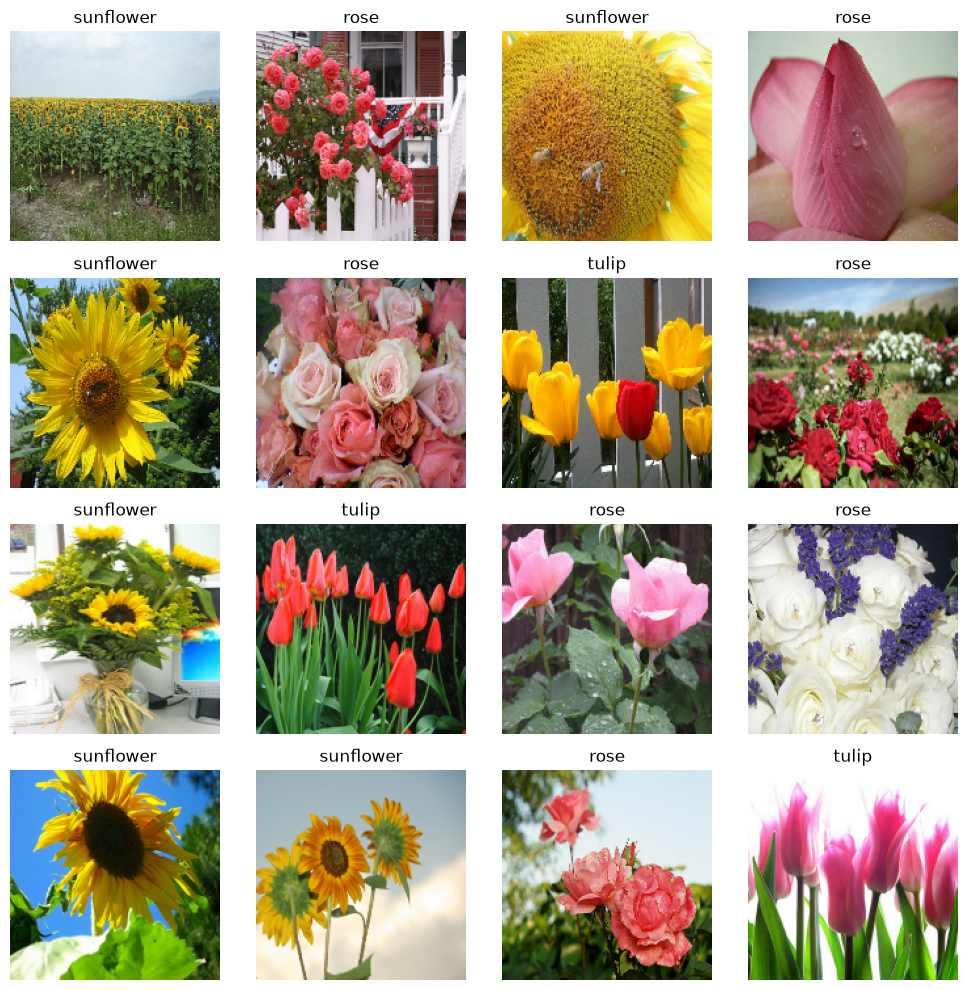

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, image, label in zip(axes.flat, images.numpy(), labels.numpy()):
    ax.imshow(image.astype("uint8"))
    ax.set_title(CLASSES[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

**What we see:** sunflowers are easy to spot by their yellow petals and the large dark centre. Roses and tulips can both
be red, pink, yellow or white; they differ mostly in **shape**: the rose has many layered petals, the tulip a closed cup
on a long stem. Backgrounds (sky, leaves, vases, people) vary a lot and are not a reliable sign.

### 3b. Colour per class

**What:** compute the mean red, green and blue value of every training photo and compare the classes.

**Decision:** a simple colour summary, because colour is the first idea for telling flowers apart, and because it decides
later whether colour changes are allowed as augmentation.

**Alternative rejected:** a colour histogram per photo. It is more detailed but much harder to read.

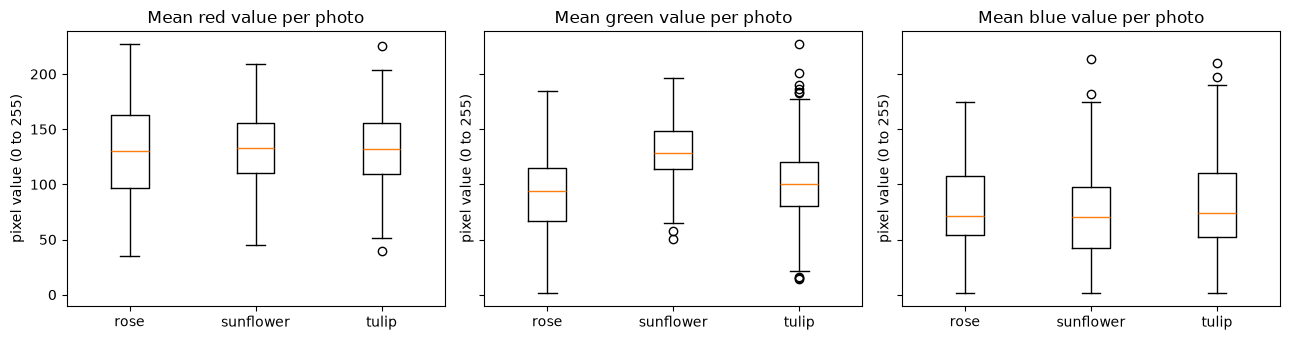

,red,green,blue
label,,,
rose,131.0,92.0,78.0
sunflower,134.0,129.0,73.0
tulip,133.0,104.0,83.0


In [8]:
colour_rows = []
for image_batch, label_batch in train_ordered:
    means = image_batch.numpy().mean(axis=(1, 2))  # mean of every channel for every photo
    for (r, g, b), label in zip(means, label_batch.numpy()):
        colour_rows.append({"label": CLASSES[label], "red": r, "green": g, "blue": b})
colours = pd.DataFrame(colour_rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, channel in zip(axes, ["red", "green", "blue"]):
    ax.boxplot([colours.query("label == @c")[channel] for c in CLASSES], tick_labels=CLASSES)
    ax.set(title=f"Mean {channel} value per photo", ylabel="pixel value (0 to 255)")
plt.tight_layout()
plt.show()
colours.groupby("label").mean().round(0)

**What we see:** the mean red value is almost the same for all three flowers (131 to 134), and so is the blue value
(73 to 83). Sunflowers stand out only by a higher **green** value (129, against 92 for roses and 104 for tulips): red plus
green is yellow. The boxes of roses and tulips lie almost on top of each other.
**Colour alone cannot separate roses from tulips**, so the model must learn shapes. This is why we use a pretrained network.
It also means that we must not destroy the colour signal of sunflowers: we will **not** use colour augmentation in step 5.

## Step 4. Repurpose a pretrained network

### 4a. The frozen base and its preprocessing

**What:** load MobileNetV2 with its ImageNet weights, without its own top (the 1000 ImageNet classes), and freeze it.

**Decisions:**
- `include_top=False`: we need our own output for 3 classes.
- `base.trainable = False`: with 300 photos, the 2.2 million weights of the base would quickly learn the training photos
  by heart. Fine-tuning the top layers of the base is a possible next step, but not part of this task.
- **Preprocessing as a layer inside the model.** MobileNetV2 expects pixels from −1 to 1. Its `preprocess_input` computes
  `x / 127.5 − 1`. We write the same as a `Rescaling(1/127.5, offset=-1)` layer. Then the saved model takes raw pixels,
  exactly what `app.py` gives it.
- **Alternative rejected:** a `Lambda` layer that calls `preprocess_input`. Keras saves the Python code of a Lambda layer
  and refuses to load it without `safe_mode=False`, so `keras.models.load_model` in the app would fail.

The next cell checks that the `Rescaling` layer gives the same numbers as `preprocess_input`.

In [9]:
base = keras.applications.MobileNetV2(input_shape=IMAGE_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False
preprocess = layers.Rescaling(1 / 127.5, offset=-1, name="preprocess")

pixels = images.numpy()
difference = np.abs(preprocess(pixels).numpy() - mobilenet_v2.preprocess_input(pixels.copy())).max()
print("Largest difference Rescaling vs. preprocess_input:", difference)
print("Base parameters: total", base.count_params(), "| trainable", sum(w.numpy().size for w in base.trainable_weights),
      "| output shape", base.output_shape)

Largest difference Rescaling vs. preprocess_input: 1.1920929e-07
Base parameters: total 2257984 | trainable 0 | output shape (None, 5, 5, 1280)


**What we see:** the largest difference between the two kinds of preprocessing is 0 (or a rounding error near 1e-7), so
the `Rescaling` layer is the same preprocessing. The frozen base has 2,257,984 parameters and **none** of them is trainable.
For a 160 × 160 photo it returns a block of 5 × 5 × 1280 numbers: 1280 feature maps on a 5 × 5 grid.

### 4b. Is the validation set independent of the training set? (near-duplicates)

**What:** pass every training and validation photo once through the frozen base, average the 5 × 5 grid
(`GlobalAveragePooling`), and compare every validation photo with every training photo by **cosine similarity**
(1 = the base sees the same thing, 0 = nothing in common).

**Why:** the flower photos come from Flickr, where people often upload several shots of the same flower. If a validation
photo is almost a copy of a training photo, the validation accuracy is too optimistic. We found no exact copies in 1a; this
step looks for near-copies.

**Decision:** we only report near-duplicates and do not move or delete files. The split is given by the course, and every
group should work on the same split.

**Alternative rejected:** comparing raw pixels. Two shots of the same flower differ in many pixels, but the base sees them
as almost the same.

In [10]:
pool = layers.GlobalAveragePooling2D()


def extract_features(dataset):
    """Base features (1280 numbers per photo) and labels from ONE loop over the dataset."""
    feats, labs = [], []
    for x, y in dataset:
        feats.append(pool(base(preprocess(x), training=False)).numpy())
        labs.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labs)


train_feats, train_labels = extract_features(train_ordered)
val_feats, val_labels = extract_features(val_ds)


def unit(f):
    return f / np.linalg.norm(f, axis=1, keepdims=True)


similarity = unit(val_feats) @ unit(train_feats).T  # 60 x 300
nearest = similarity.argmax(axis=1)
best_sim = similarity.max(axis=1)
print("Highest similarity of each validation photo to a training photo:")
print(pd.Series(best_sim).describe().round(3).to_string())
within = unit(train_feats) @ unit(train_feats).T
np.fill_diagonal(within, -1)  # a photo is not its own neighbour
print("Inside the training set: photos with a partner above 0.9:", (within.max(axis=1) > 0.9).sum(),
      "| highest similarity:", round(float(within.max()), 3))

Highest similarity of each validation photo to a training photo:
count    60.000
mean      0.630
std       0.086
min       0.394
25%       0.569
50%       0.648
75%       0.696
max       0.790
Inside the training set: photos with a partner above 0.9: 6 | highest similarity: 0.997


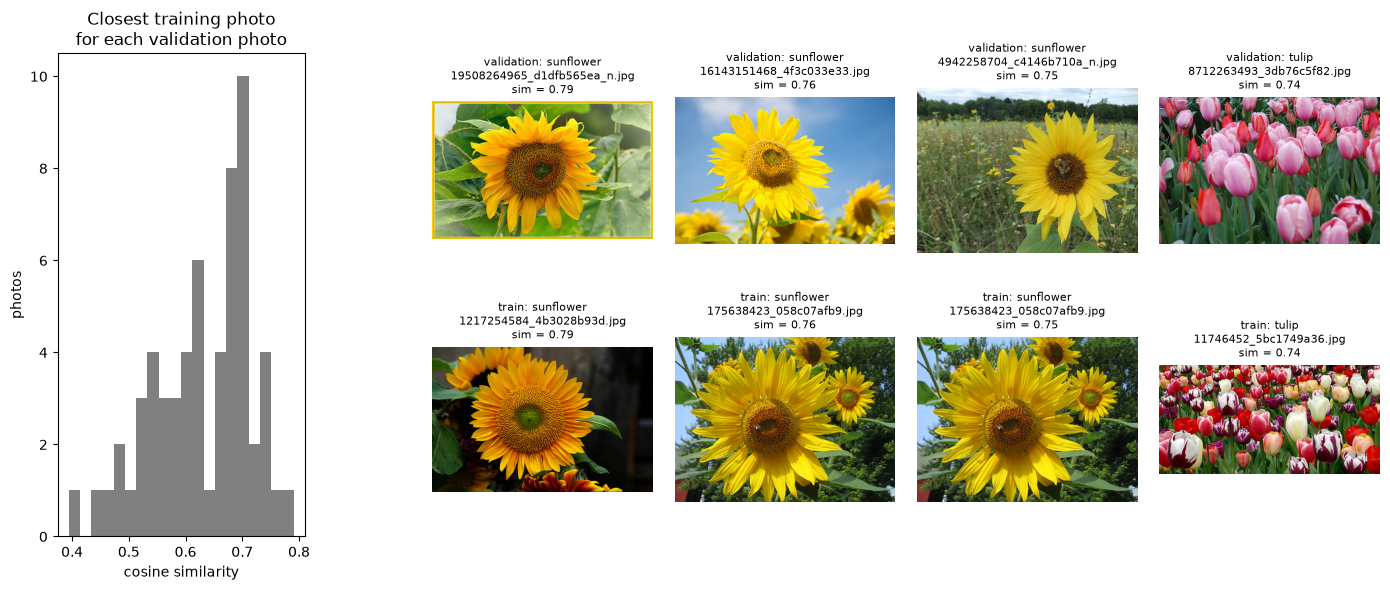

In [11]:
order = np.argsort(best_sim)[::-1][:4]
fig, axes = plt.subplots(2, 5, figsize=(14, 6), gridspec_kw={"width_ratios": [1.6, 1, 1, 1, 1]})
for ax in axes[:, 0]:
    ax.remove()
hist_ax = fig.add_subplot(1, 5, 1)
hist_ax.hist(best_sim, bins=20, color="grey")
hist_ax.set(title="Closest training photo\nfor each validation photo", xlabel="cosine similarity", ylabel="photos")
for col, i in enumerate(order, start=1):
    for row, (split, path) in enumerate([("validation", val_ds.file_paths[i]),
                                         ("train", train_ordered.file_paths[nearest[i]])]):
        axes[row, col].imshow(Image.open(path))
        axes[row, col].set_title(f"{split}: {Path(path).parent.name}\n{Path(path).name}\nsim = {best_sim[i]:.2f}",
                                 fontsize=8)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

**What we see:** the highest similarity of a validation photo to any training photo is 0.79, the median
0.65. The four closest pairs in the figure show the same kind of flower in a similar scene, but they are clearly
**different photos**. So the validation set is independent of the training set.
Inside the training set, however, 6 photos have a partner above 0.9 (the highest pair: 0.997, almost a copy). In the
cross-validation of 4c such a pair can land in two different folds, which makes the cross-validation look a little too
good. We therefore use the cross-validation only to **compare** heads with each other, never as an estimate of the
accuracy. We do not delete these photos, because the course gives the split.

### 4c. Choose the head, dropout, learning rate and number of epochs (cross-validation on the training set)

**What:** before we build the final model, we try a few heads on the 300 training photos only. Because the base is frozen
and we do not augment yet, the base turns every photo into the **same 1280 numbers in every epoch**. We computed them once
in 4b (`train_feats`), so a head trains in a few seconds. This trick is called **feature extraction** (Keras guide
"Transfer learning and fine-tuning"); it gives exactly the same head as training the full model without augmentation.

We use **5-fold cross-validation** (`StratifiedKFold` from scikit-learn): the 300 photos are split into 5 parts with
20 photos per class each; every part is used once for checking while the head trains on the other 4 parts.

**Decision:** we do not use the 60 validation photos here. They stay for the choice between the models in step 5.

**Alternative rejected:** tuning on the validation set. Then the same 60 photos would choose the head, the learning rate
**and** the model, and the validation accuracy would become too optimistic.

**The candidates** (we change one thing at a time, starting from the Keras tutorial's head: pooling, dropout 0.2,
one `Dense` layer with softmax, Adam with learning rate 0.001):

| Name | Head | Dropout | Learning rate |
|---|---|---|---|
| `linear d0.2 lr1e-3` (start) | Dense(3) | 0.2 | 0.001 |
| `linear d0.0 lr1e-3` | Dense(3) | 0.0 | 0.001 |
| `linear d0.5 lr1e-3` | Dense(3) | 0.5 | 0.001 |
| `linear d0.2 lr1e-4` | Dense(3) | 0.2 | 0.0001 |
| `linear d0.2 lr1e-2` | Dense(3) | 0.2 | 0.01 |
| `hidden128 d0.2 lr1e-3` | Dense(128, relu) + Dense(3) | 0.2 | 0.001 |

**Rule (one-standard-error rule):** find the lowest mean cross-validation loss over all candidates and epochs. Every
candidate whose best loss is within one standard error (over the 5 folds) of it counts as equally good. Among those we keep
the start configuration if it is there, and we prefer the linear head to the hidden layer (fewer parameters).

In [12]:
HEAD_CONFIGS = {
    "linear d0.2 lr1e-3": dict(hidden=0, dropout=0.2, lr=1e-3),
    "linear d0.0 lr1e-3": dict(hidden=0, dropout=0.0, lr=1e-3),
    "linear d0.5 lr1e-3": dict(hidden=0, dropout=0.5, lr=1e-3),
    "linear d0.2 lr1e-4": dict(hidden=0, dropout=0.2, lr=1e-4),
    "linear d0.2 lr1e-2": dict(hidden=0, dropout=0.2, lr=1e-2),
    "hidden128 d0.2 lr1e-3": dict(hidden=128, dropout=0.2, lr=1e-3),
}
CV_EPOCHS = 60


def build_head(hidden, dropout, lr):
    """The head alone, for 1280 pooled features (used only for the cross-validation)."""
    head = keras.Sequential([keras.Input((1280,))])
    if hidden:
        head.add(layers.Dense(hidden, activation="relu"))
    head.add(layers.Dropout(dropout))
    head.add(layers.Dense(3, activation="softmax"))
    head.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return head


folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(train_feats, train_labels))
cv_curves = {}
for name, cfg in HEAD_CONFIGS.items():
    losses, accs = [], []
    for k, (fit_idx, check_idx) in enumerate(folds):
        keras.utils.set_random_seed(SEED + k)
        head = build_head(**cfg)
        h = head.fit(train_feats[fit_idx], train_labels[fit_idx], batch_size=32, epochs=CV_EPOCHS, verbose=0,
                     validation_data=(train_feats[check_idx], train_labels[check_idx]))
        losses.append(h.history["val_loss"])
        accs.append(h.history["val_accuracy"])
    cv_curves[name] = (np.array(losses), np.array(accs))  # shape: 5 folds x 60 epochs

E0000 00:00:1793356827.078654 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793356836.469341 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793356843.612747 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793356852.179955 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793356861.157296 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


...

E0000 00:00:1793357051.028798 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793357058.281206 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793357065.631445 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793357073.600465 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793357082.032729 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


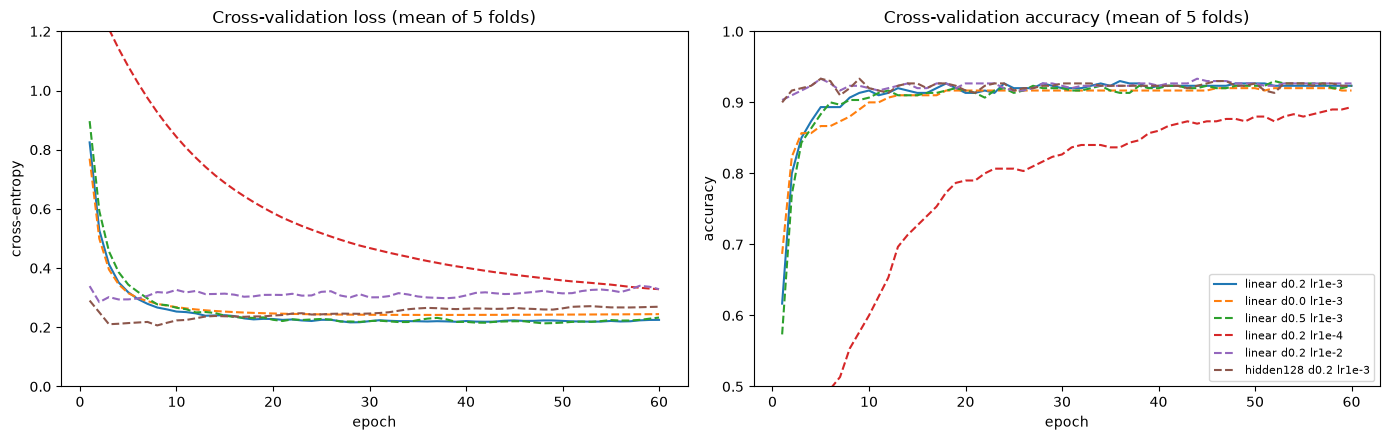

,best epoch,CV loss,SE of loss,CV accuracy,within 1 SE of best
candidate,,,,,
linear d0.2 lr1e-3,28,0.217,0.014,0.927,True
linear d0.0 lr1e-3,37,0.242,0.039,0.917,True
linear d0.5 lr1e-3,48,0.213,0.025,0.923,True
linear d0.2 lr1e-4,60,0.329,0.015,0.893,False
linear d0.2 lr1e-2,2,0.285,0.046,0.910,False
hidden128 d0.2 lr1e-3,8,0.206,0.044,0.920,True


In [13]:
cv_rows = []
for name, (losses, accs) in cv_curves.items():
    mean_loss = losses.mean(axis=0)
    best_epoch = int(mean_loss.argmin())
    cv_rows.append({"candidate": name, "best epoch": best_epoch + 1, "CV loss": mean_loss[best_epoch],
                    "SE of loss": losses[:, best_epoch].std(ddof=1) / np.sqrt(len(folds)),
                    "CV accuracy": accs[:, best_epoch].mean()})
cv_table = pd.DataFrame(cv_rows).set_index("candidate")
limit = cv_table["CV loss"].min() + cv_table.loc[cv_table["CV loss"].idxmin(), "SE of loss"]
cv_table["within 1 SE of best"] = cv_table["CV loss"] <= limit

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, (losses, accs) in cv_curves.items():
    style = "-" if name.startswith("linear d0.2 lr1e-3") else "--"
    axes[0].plot(range(1, CV_EPOCHS + 1), losses.mean(axis=0), style, label=name)
    axes[1].plot(range(1, CV_EPOCHS + 1), accs.mean(axis=0), style, label=name)
axes[0].set(title="Cross-validation loss (mean of 5 folds)", xlabel="epoch", ylabel="cross-entropy", ylim=(0, 1.2))
axes[1].set(title="Cross-validation accuracy (mean of 5 folds)", xlabel="epoch", ylabel="accuracy", ylim=(0.5, 1))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
cv_table.round(3)

**What we see:** 
- The start configuration (`linear d0.2 lr1e-3`) reaches a mean cross-validation loss of 0.217 (accuracy 0.927) at
  epoch 28. The lowest loss of all has the hidden layer (0.206), but its standard error is 0.044, and the start
  configuration lies within one standard error. Dropout 0.0 (0.242) and 0.5 (0.213) are also within one standard error.
- Learning rate 0.0001 is too slow: after 60 epochs the loss is still 0.329. Learning rate 0.01 is too fast: the loss is
  lowest at epoch 2 (0.285) and then rises again; the hidden layer behaves the same way from epoch 8 on.
- **Decision:** following our rule, we keep the start configuration: **linear head, dropout 0.2, learning rate 0.001**.
  The hidden layer would add 164,355 trainable parameters for no clear gain.
- **Epochs:** with the chosen head, the loss falls quickly until about epoch 10 and is flat from epoch 20 to 60. So
  **50 epochs** is a safe upper limit, and early stopping will usually stop much earlier.

### 4d. Build the full model and count its parameters

**What:** put everything into one model: raw pixels → (augmentation, only in step 5) → `Rescaling` → frozen MobileNetV2 →
`GlobalAveragePooling2D` → `Dropout` → `Dense(3, softmax)`.

**Decisions:**
- `base(x, training=False)`: the `BatchNormalization` layers of the base keep using their ImageNet statistics, also during
  training. Otherwise they would learn new statistics from our small batches and damage the pretrained features
  (Keras transfer-learning guide).
- `GlobalAveragePooling2D` instead of `Flatten`: Flatten would give 5 × 5 × 1280 = 32,000 inputs to the Dense layer and
  96,003 weights, which is far too many for 300 photos.
- `softmax` output: one probability per flower, as the app expects.
- **Every model uses the same frozen `base` object**, so training, validation and test images go through the same base.

The function `build_model` builds both models of the task: with `augment=None` the dense-head model of step 4, with an
augmentation block the model of step 5.

In [14]:
HEAD = dict(dropout=0.2, lr=1e-3)  # chosen in 4c


def build_model(augment=None, name="dense_head"):
    inputs = keras.Input(IMAGE_SIZE + (3,), name="raw_pixels")  # raw pixels 0..255, as in app.py
    x = augment(inputs) if augment is not None else inputs
    x = preprocess(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(HEAD["dropout"])(x)
    outputs = layers.Dense(len(CLASSES), activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(optimizer=keras.optimizers.Adam(HEAD["lr"]), loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model


def count_params(model):
    trainable = sum(w.numpy().size for w in model.trainable_weights)
    return model.count_params(), trainable


model = build_model()
model.summary()
total, trainable = count_params(model)
by_hand = 1280 * 3 + 3  # 1280 inputs x 3 outputs (weights) + 3 biases
print(f"Total {total:,} | trainable {trainable:,} | frozen {total - trainable:,} | head by hand: {by_hand:,}")
assert trainable == by_hand

Model: "dense_head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ raw_pixels (InputLayer)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Rescaling)          │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Total 2,261,827 | trainable 3,843 | frozen 2,257,984 | head by hand: 3,843


**What we see:** the model has 2,261,827 parameters in total, but only **3,843 are trainable**. We can count them by hand:
the pooling gives 1280 numbers; every one of the 3 outputs has one weight per number (1280 × 3 = 3,840) plus one bias
(3), so 3,840 + 3 = **3,843**. `Rescaling`, pooling and dropout have no parameters. The other 2,257,984 parameters belong
to the frozen base (2,223,872 weights + 34,112 `BatchNormalization` statistics). 3,843 trainable parameters for 300
photos is a small number, so strong overfitting is not likely.

### 4e. Train the dense-head model and plot its learning curves

**What:** train the model on the training photos and check it on the validation photos after every epoch.

**Decision on the number of epochs:** at most 50 epochs with `EarlyStopping` on the validation loss, `patience=5`, and
`restore_best_weights=True`: training stops when the validation loss has not improved for 5 epochs, and the model goes back
to the weights of its best epoch. The cross-validation in 4c shows when the loss stops falling, so 50 is a safe upper limit.

**Alternative rejected:** a fixed number of epochs taken from 4c. It would keep the validation photos completely out of
training, but the task asks for `EarlyStopping`. The price: the validation loss chooses the stopping epoch, so the
validation accuracy is a little optimistic. The test set in step 6 does not have this problem.

**Seeds:** we train the model once with seed 42 (this is the model we save and use) and twice more with seeds 43 and 44,
only to measure how much the result depends on the seed (5b).

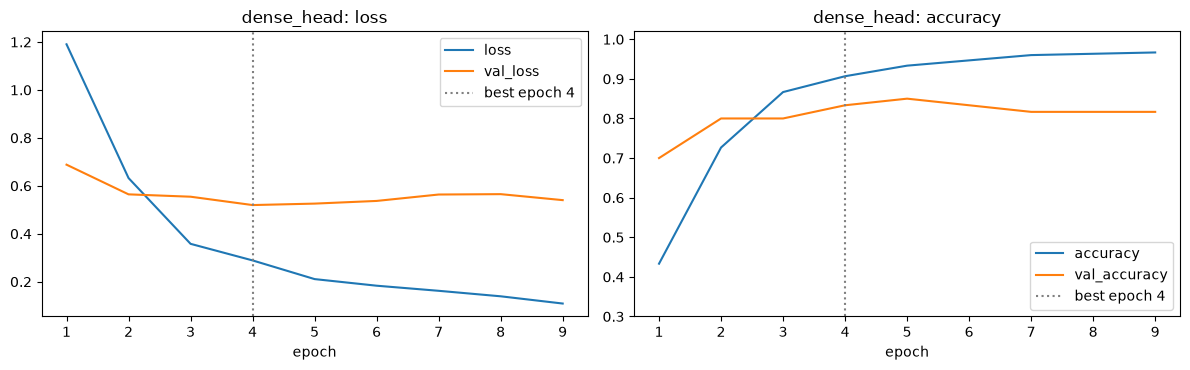

accuracy        0.907
loss            0.289
val_accuracy    0.833
val_loss        0.520
Name: 4, dtype: float64

In [15]:
MAX_EPOCHS = 50


def train(model, seed):
    keras.utils.set_random_seed(seed)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    return model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, callbacks=[stop], verbose=0)


def plot_curves(history, title):
    hist = pd.DataFrame(history.history)
    hist.index += 1
    best = int(hist["val_loss"].idxmin())
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    hist[["loss", "val_loss"]].plot(ax=axes[0], title=f"{title}: loss", xlabel="epoch")
    hist[["accuracy", "val_accuracy"]].plot(ax=axes[1], title=f"{title}: accuracy", xlabel="epoch", ylim=(0.3, 1.02))
    for ax in axes:
        ax.axvline(best, color="grey", linestyle=":", label=f"best epoch {best}")
        ax.legend()
    plt.tight_layout()
    plt.show()
    return hist.loc[best]


keras.utils.set_random_seed(SEED)
dense_head = build_model(name="dense_head")
history_dense = train(dense_head, SEED)
plot_curves(history_dense, "dense_head").round(3)

**What we see:** the validation loss is lowest at **epoch 4** (0.520, validation accuracy 0.833);
early stopping waited 5 more epochs and went back to epoch 4. The training loss keeps falling (to about 0.1 at epoch 9),
while the validation loss stays flat around 0.52 to 0.57 and the validation accuracy stays at 0.80 to 0.85.
**Does it overfit?** A little: after epoch 4 the model gets better on the training photos (accuracy 0.97) but not on the
validation photos; early stopping prevents the worst of it.

**Note:** the cross-validation in 4c (inside the training set) gave a loss of 0.22 and an accuracy of 0.93. On the
validation photos we get 0.52 and 0.83. Part of this gap comes from the near-copies inside the training set (4b); part is
chance, because 60 photos are few (one standard error of an accuracy near 0.83 on 60 photos is about 0.05); and step 5f
shows a third reason: the validation set contains photos of a kind that is rare in training (tulips seen from far away in
parks). The validation numbers are the more realistic ones.

**Save the model.** `model.save` writes the model with its preprocessing and its frozen base into one `.keras` file.
The app and step 6 load it from there.

In [16]:
dense_head.save(MODELS / "dense_head.keras")
print(sorted(p.name for p in MODELS.glob("*.keras")))

['dense_head.keras', 'dense_head_aug.keras']


**What we see:** the file `models/dense_head.keras` exists.

## Step 5. Improve the model with data augmentation

### 5a. Which augmentations?

**What:** show one training photo with eight random augmentations.

**Decisions:**
- `RandomFlip("horizontal")`: a flower mirrored left–right is still the same flower.
- `RandomRotation(0.1)`: turns by up to ±10 % of a full turn (±36°); photos are taken at slight angles.
- `RandomZoom(0.1)`: zooms in or out by up to 10 %; customers stand closer or farther away.
- These layers are active **only during training**. In `predict` and in the app they let the photo pass unchanged, so
  validation and test photos are prepared exactly as before.

**Alternatives rejected:**
- Vertical flip: flowers upside down (with the sky at the bottom) do not appear in customer photos.
- Colour changes (`RandomBrightness`, `RandomContrast`, hue): step 3b shows that colour is the clearest sign of a sunflower;
  we do not want to blur it.
- Stronger rotation or zoom: it would cut the flower out of the frame in close-ups.

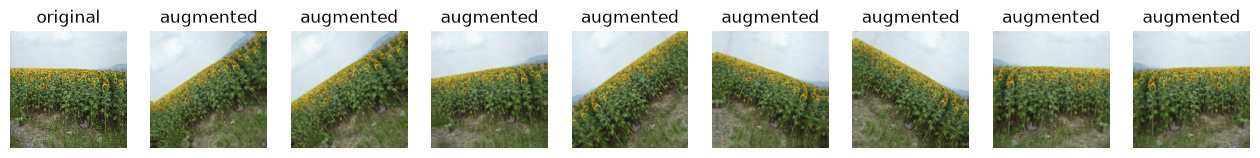

In [17]:
augment = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.1), layers.RandomZoom(0.1)],
                           name="augmentation")
keras.utils.set_random_seed(SEED)
photo = images[:1]
fig, axes = plt.subplots(1, 9, figsize=(16, 2.2))
axes[0].imshow(photo[0].numpy().astype("uint8"))
axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(augment(photo, training=True)[0].numpy().clip(0, 255).astype("uint8"))
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.show()

**What we see:** the augmented photos are mirrored, slightly turned and zoomed, but every one still clearly shows the same
flower. The corners are filled by reflecting the photo (`fill_mode="reflect"`, the default).

### 5b. Train the augmented model, save it, and compare learning curves

**What:** the same model as in step 4, with the augmentation block in front of the preprocessing, trained with the same
rules (seed 42, at most 50 epochs, early stopping). The head and the frozen base are the same, so the number of parameters
is the same.

**Decision:** same head, dropout and learning rate as step 4, so that the only difference is the augmentation.
**Alternative rejected:** re-tuning the head for the augmented model; then we could not say what the augmentation alone
brings.

dense_head_aug: total 2,261,827 | trainable 3,843


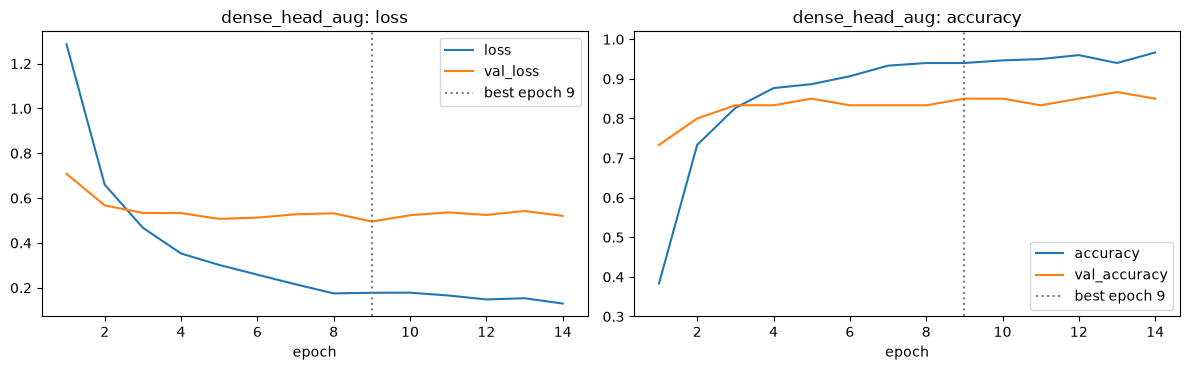

accuracy        0.940
loss            0.178
val_accuracy    0.850
val_loss        0.495
Name: 9, dtype: float64

In [18]:
keras.utils.set_random_seed(SEED)
dense_head_aug = build_model(augment, name="dense_head_aug")
history_aug = train(dense_head_aug, SEED)
dense_head_aug.save(MODELS / "dense_head_aug.keras")
total, trainable = count_params(dense_head_aug)
print(f"dense_head_aug: total {total:,} | trainable {trainable:,}")
plot_curves(history_aug, "dense_head_aug").round(3)

**What we see:** the augmented model has its lowest validation loss at **epoch 9** (0.495, validation
accuracy 0.850) and stops after 14 epochs. It learns more slowly than the model without augmentation, because every epoch
shows it slightly different photos, and its training loss stays higher for longer. The gap between training and
validation is a bit smaller. It has exactly the same parameters as `dense_head`: 2,261,827 in total, 3,843 trainable
(augmentation layers have no parameters).

### 5c. How much does the seed change the result?

**What:** train both models again with seeds 43 and 44 and collect the best validation accuracy and loss of all six runs.

**Why:** a difference between two models only matters if it is larger than the difference between two runs of the same
model. The repeats are saved in `models/seed_repeats/` (so that the app's model list in `models/` stays short), and they
are evaluated on the test set in step 6 as well, to show the seed spread there too. They are **not** candidates for the
choice: the candidates are the two models with seed 42.

In [19]:
REPEAT_SEEDS = [43, 44]
(MODELS / "seed_repeats").mkdir(exist_ok=True)
seed_rows = []
for name, hist in [("dense_head", history_dense), ("dense_head_aug", history_aug)]:
    best = int(np.argmin(hist.history["val_loss"]))
    seed_rows.append({"model": name, "seed": SEED, "val_loss": hist.history["val_loss"][best],
                      "val_accuracy": hist.history["val_accuracy"][best], "epochs": len(hist.history["loss"])})
for seed in REPEAT_SEEDS:
    for name, aug in [("dense_head", None), ("dense_head_aug", augment)]:
        keras.utils.set_random_seed(seed)
        repeat = build_model(aug, name=name)
        hist = train(repeat, seed)
        repeat.save(MODELS / "seed_repeats" / f"{name}_seed{seed}.keras")
        best = int(np.argmin(hist.history["val_loss"]))
        seed_rows.append({"model": name, "seed": seed, "val_loss": hist.history["val_loss"][best],
                          "val_accuracy": hist.history["val_accuracy"][best], "epochs": len(hist.history["loss"])})
seeds = pd.DataFrame(seed_rows)
seeds.round(3)

,model,seed,val_loss,val_accuracy,epochs
0,dense_head,42,0.520,0.833,9
1,dense_head_aug,42,0.495,0.850,14
2,dense_head,43,0.591,0.800,12
3,dense_head_aug,43,0.517,0.817,15
4,dense_head,44,0.584,0.833,11
5,dense_head_aug,44,0.544,0.833,10


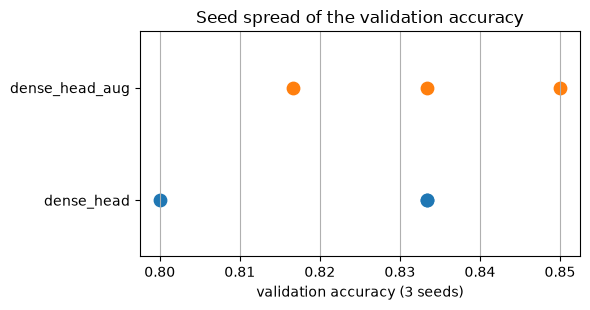

val_accuracy        val_loss       
                       mean    std     mean    std
model                                             
dense_head            0.822  0.019    0.565  0.039
dense_head_aug        0.833  0.017    0.519  0.024

In [20]:
seed_summary = seeds.groupby("model")[["val_accuracy", "val_loss"]].agg(["mean", "std"])
fig, ax = plt.subplots(figsize=(6, 3.2))
for i, name in enumerate(["dense_head", "dense_head_aug"]):
    acc = seeds.query("model == @name")["val_accuracy"]
    ax.scatter(acc, [i] * len(acc), s=80)
ax.set(yticks=[0, 1], yticklabels=["dense_head", "dense_head_aug"], ylim=(-0.5, 1.5),
       xlabel="validation accuracy (3 seeds)", title="Seed spread of the validation accuracy")
ax.grid(axis="x")
plt.tight_layout()
plt.show()
seed_summary.round(3)

**What we see:** over the three seeds, `dense_head` reaches a validation accuracy of 0.800 to 0.833
(mean 0.822, standard deviation 0.019) and `dense_head_aug` 0.817 to 0.850 (mean 0.833, standard deviation 0.017).
The augmented model is ahead by about 0.011 on average, which is less than **one** photo (0.017), and the two ranges
overlap. Its validation loss is a little lower in all three seeds (mean 0.519 against 0.565). So augmentation may help a
little, but the seed alone moves the accuracy by up to 0.033 (two photos).

### 5d. Choose the model (paired comparison on the validation photos)

**What:** load both saved candidates from disk and predict the 60 validation photos. Then compare them **photo by photo**.

**New tool: the paired bootstrap.** We draw 60 validation photos *with replacement* (some twice, some not at all), compute
the accuracy of both models on **the same** draw, and note the difference. After 10,000 draws, the middle 95 % of these
differences is the 95 % interval. "Paired" means both models are always judged on the same photos, so the difficulty of
the photos cancels out. If the interval contains 0, the data cannot tell the two models apart.

**Decision:** we use the models loaded from the files, not the ones in memory. This checks that saving and loading work,
and it means the numbers come from the same files the app will use.

**The function `predict_dataset`** collects images, labels and probabilities in **one** loop over a dataset, so that they
always belong together. We use it unchanged for the test set in step 6; running it here on the validation set is its trial
run before the single test access.

In [21]:
def predict_dataset(model, dataset):
    """Images, true labels and predicted probabilities from ONE loop over the dataset."""
    imgs, labs, probs = [], [], []
    for x, y in dataset:
        imgs.append(x.numpy())
        labs.append(y.numpy())
        probs.append(np.asarray(model.predict_on_batch(x)))
    return np.concatenate(imgs), np.concatenate(labs), np.concatenate(probs)


def paired_bootstrap(correct_a, correct_b, n_boot=10_000, seed=SEED):
    """95 % interval of accuracy(a) - accuracy(b), with both models judged on the same resampled photos."""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(correct_a), size=(n_boot, len(correct_a)))
    diff = correct_a[idx].mean(axis=1) - correct_b[idx].mean(axis=1)
    return np.percentile(diff, [2.5, 97.5])


CANDIDATES = ["dense_head", "dense_head_aug"]
val_pred = {}
for name in CANDIDATES:
    loaded = keras.models.load_model(MODELS / f"{name}.keras")
    val_images, y_val, p_val = predict_dataset(loaded, val_ds)
    val_pred[name] = p_val
rng = np.random.default_rng(SEED)
val_pred["random_baseline"] = np.eye(3)[rng.integers(0, 3, size=len(y_val))]  # a random guess as "probability" 1

val_correct = {name: (p.argmax(axis=1) == y_val).astype(float) for name, p in val_pred.items()}
low, high = paired_bootstrap(val_correct["dense_head_aug"], val_correct["dense_head"])
print({name: round(c.mean(), 3) for name, c in val_correct.items()})
print(f"Accuracy difference aug - plain: {val_correct['dense_head_aug'].mean() - val_correct['dense_head'].mean():+.3f}, "
      f"95 % interval [{low:+.3f}, {high:+.3f}]")
both = pd.crosstab(pd.Series(val_correct["dense_head"], name="dense_head correct"),
                   pd.Series(val_correct["dense_head_aug"], name="dense_head_aug correct"))
both

{'dense_head': np.float64(0.833), 'dense_head_aug': np.float64(0.85), 'random_baseline': np.float64(0.383)}
Accuracy difference aug - plain: +0.017, 95 % interval [-0.033, +0.067]


dense_head_aug correct,0.0,1.0
dense_head correct,,
0.0,8,2
1.0,1,49


In [22]:
mean_acc = seeds.groupby("model")["val_accuracy"].mean()
rule_a = low > 0
rule_b = mean_acc["dense_head_aug"] > mean_acc["dense_head"]
BEST = "dense_head_aug" if (rule_a and rule_b) else "dense_head"
print(f"(a) paired interval fully above 0: {rule_a} | (b) higher mean over 3 seeds: {rule_b} -> chosen model: {BEST}")

(a) paired interval fully above 0: False | (b) higher mean over 3 seeds: True -> chosen model: dense_head


**What we see:** on the 60 validation photos, the loaded `dense_head` gets 0.833 right (50 photos) and
`dense_head_aug` 0.850 (51 photos). Random guessing gets 0.383. The two models agree on 57 of 60 photos: 49 right for
both, 8 wrong for both. The augmented model is right on 2 photos where the plain one is wrong, and wrong on 1 photo where
the plain one is right: a net difference of **one photo**. The paired 95 % interval of the difference goes from −0.033 to
+0.067 and contains 0.

**Decision:** condition (a) is not met, so by our rule we keep the simpler model: **`dense_head`** (without augmentation).
This does not mean that augmentation is useless; it means that 60 photos cannot show a gain of this size. (A larger
validation set or cross-validation of the full model with augmentation could; on a laptop CPU this would take much longer.)

### 5e. Success criterion on the validation set

**What:** check the success criterion that we fixed before the first model, for the chosen model.

In [23]:
low_b, high_b = paired_bootstrap(val_correct[BEST], val_correct["random_baseline"])
criterion = pd.DataFrame([
    {"condition": "validation accuracy >= 0.80", "value": round(val_correct[BEST].mean(), 3),
     "met": val_correct[BEST].mean() >= 0.80},
    {"condition": "paired 95 % interval vs. random guessing fully above 0",
     "value": f"[{low_b:+.3f}, {high_b:+.3f}]", "met": low_b > 0},
])
criterion

,condition,value,met
0,validation accuracy >= 0.80,0.833,True
1,paired 95 % interval vs. random guessing fully...,"[+0.300, +0.600]",True


**What we see:** the chosen model `dense_head` reaches a validation accuracy of 0.833 (at least 0.80
required) and is ahead of random guessing by 0.30 to 0.60 (paired 95 % interval, fully above 0). Both conditions are
met. The binding condition is the first one: 0.833 is only two photos above 0.80.

**Null test (shuffled labels).** A check of the whole chain: we train the chosen head on the training features with
**shuffled** labels. Such a head cannot learn anything real, so it must not beat random guessing on the validation photos.
If it did, something in our chain (for example a mix-up of photos and labels) would leak the answer.
**Alternative rejected:** skipping this check; it costs a few seconds and would catch a serious error.

In [24]:
keras.utils.set_random_seed(SEED)
shuffled = np.random.default_rng(SEED).permutation(train_labels)
null_head = build_head(hidden=0, dropout=HEAD["dropout"], lr=HEAD["lr"])
null_head.fit(train_feats, shuffled, batch_size=32, epochs=30, verbose=0)
assert (val_labels == y_val).all()  # same order of validation photos everywhere
null_acc = accuracy_score(y_val, null_head.predict(val_feats, verbose=0).argmax(axis=1))
print(f"Validation accuracy with shuffled training labels: {null_acc:.3f} (random guessing: 0.333)")

E0000 00:00:1793357446.762332 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Validation accuracy with shuffled training labels: 0.367 (random guessing: 0.333)


**What we see:** with shuffled labels the head reaches 0.367 on the validation photos (22 of 60), close to
random guessing (0.333) and far below the real model (0.833). The chain does not leak the answer.

### 5f. When should a member of staff check the answer? (threshold fixed on the validation set)

**What:** for the chosen model, plot the highest probability of every validation photo, separately for correct and wrong
answers, and the accuracy among the photos the model would answer alone for every threshold.

**Decision rule (fixed now, before the test):** the **threshold** is the lowest value in 0.50, 0.55, …, 0.95 at which the
photos above it reach at least **95 % accuracy** on the validation set. Photos below the threshold go to a member of staff.

If no threshold reaches 95 %, we take the strictest one, 0.95, and say clearly that the probability is not a reliable
warning sign (this fallback is part of the code below).

**Alternative rejected:** a fixed number such as 0.9 without looking at the data; it could send far too many or far too few
photos to staff. Caveat: 60 photos with only a few errors give a rough threshold; we check it once on the test set.

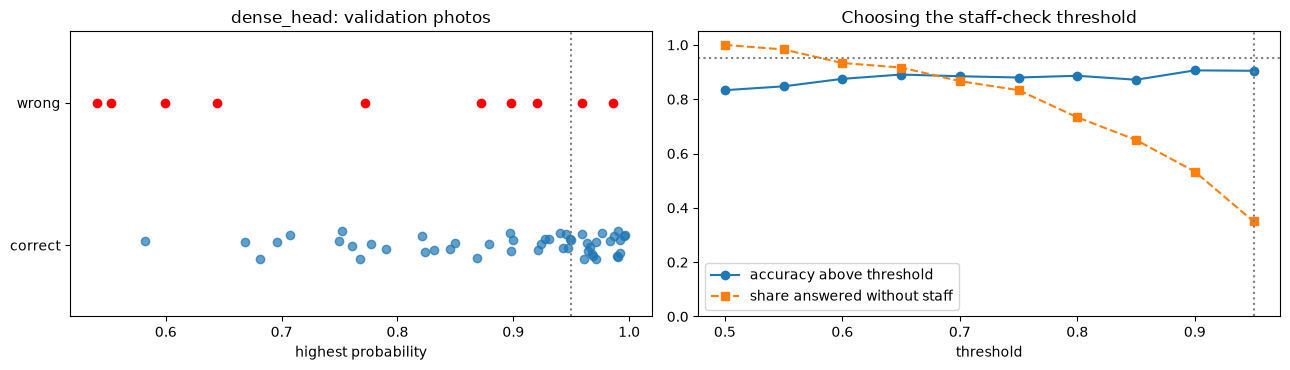

Threshold: 0.95


,0,1,2,3,4,5,6,7,8,9
threshold,0.500,0.550,0.600,0.650,0.700,0.750,0.800,0.850,0.900,0.950
share answered alone,1.000,0.983,0.933,0.917,0.867,0.833,0.733,0.650,0.533,0.350
accuracy above,0.833,0.847,0.875,0.891,0.885,0.880,0.886,0.872,0.906,0.905


In [25]:
p_best = val_pred[BEST]
confidence = p_best.max(axis=1)
correct = val_correct[BEST].astype(bool)
thresholds = np.round(np.arange(0.50, 0.96, 0.05), 2)
coverage = [(confidence >= t).mean() for t in thresholds]
acc_above = [correct[confidence >= t].mean() if (confidence >= t).any() else np.nan for t in thresholds]
THRESHOLD = next((t for t, a in zip(thresholds, acc_above) if a >= 0.95), 0.95)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].scatter(confidence[correct], np.zeros(correct.sum()) + np.random.default_rng(0).uniform(-.1, .1, correct.sum()),
                label="correct", alpha=0.7)
axes[0].scatter(confidence[~correct], np.ones((~correct).sum()), color="red", label="wrong")
axes[0].axvline(THRESHOLD, color="grey", linestyle=":")
axes[0].set(yticks=[0, 1], yticklabels=["correct", "wrong"], ylim=(-0.5, 1.5), xlabel="highest probability",
            title=f"{BEST}: validation photos")
axes[1].plot(thresholds, acc_above, "o-", label="accuracy above threshold")
axes[1].plot(thresholds, coverage, "s--", label="share answered without staff")
axes[1].axhline(0.95, color="grey", linestyle=":")
axes[1].axvline(THRESHOLD, color="grey", linestyle=":")
axes[1].set(xlabel="threshold", ylim=(0, 1.05), title="Choosing the staff-check threshold")
axes[1].legend()
plt.tight_layout()
plt.show()
print("Threshold:", THRESHOLD)
pd.DataFrame({"threshold": thresholds, "share answered alone": coverage, "accuracy above": acc_above}).round(3).T

**What we see:** the 10 wrong validation photos are **not** all unsure: 5 of them have a highest
probability below 0.8, but 5 have 0.87 to 0.99. The accuracy among the photos the model answers alone rises only from
0.833 (threshold 0.50, all photos) to about 0.90 (thresholds 0.90 and 0.95). **No threshold reaches 95 %**, so by our
rule the threshold is the strictest one, **0.95**: the model answers 35 % of the photos alone (21 of 60), and of those
about 1 in 10 is still wrong. In plain words: the probability helps a little, but a high probability does not guarantee a
right answer. The next cell shows which photos these confident errors are.

### 5g. Which validation photos does the chosen model get wrong?

**What:** show all wrong validation photos of the chosen model, with the true class, the prediction and its probability.

**Why:** this tells us, before the test, what kind of photo is difficult, so that the test errors in step 6 can be compared
with it. **Alternative rejected:** only counting the errors per class; the counts do not show *why* a photo is hard.

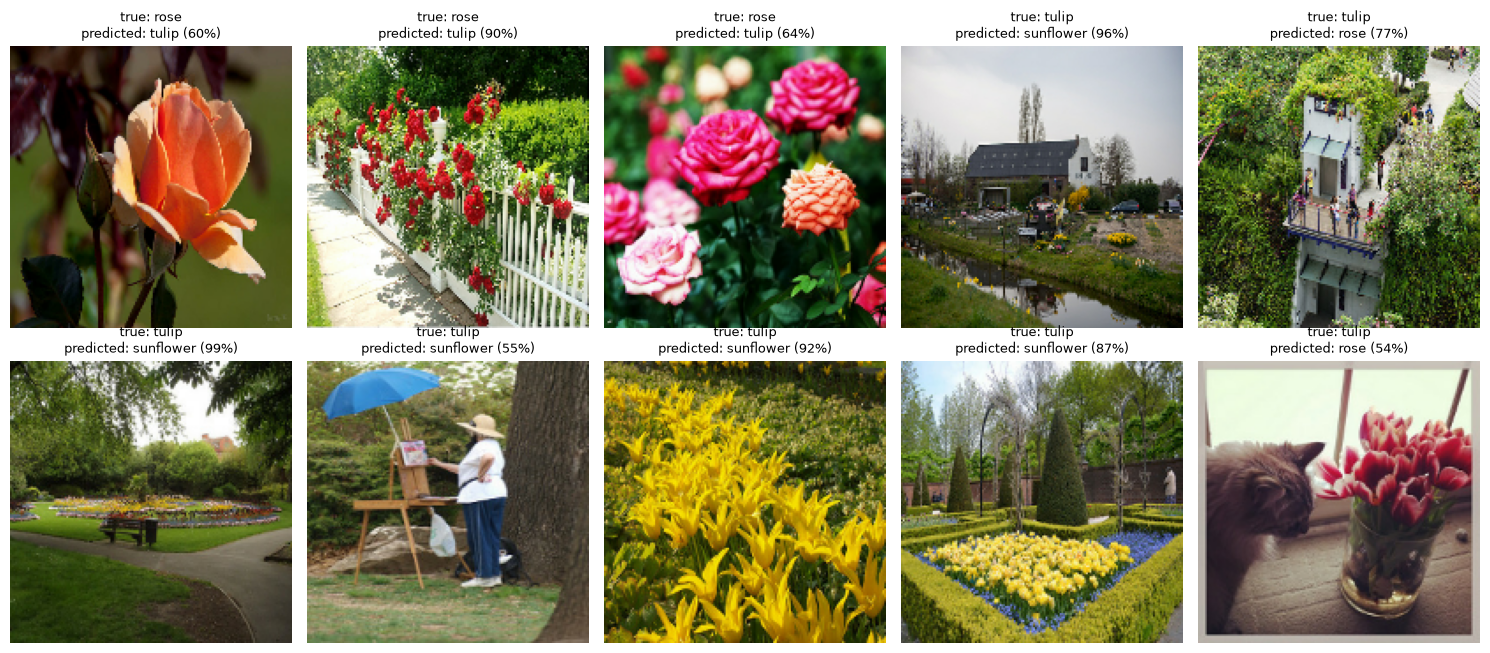

predicted,rose,sunflower,tulip
true,,,
rose,17,0,3
sunflower,0,20,0
tulip,2,5,13


In [26]:
y_val_pred = val_pred[BEST].argmax(axis=1)
val_wrong = np.flatnonzero(y_val_pred != y_val)
fig, axes = plt.subplots(2, (len(val_wrong) + 1) // 2, figsize=(3 * ((len(val_wrong) + 1) // 2), 6.6), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, val_wrong):
    ax.imshow(val_images[i].astype("uint8"))
    ax.set_title(f"true: {CLASSES[y_val[i]]}\npredicted: {CLASSES[y_val_pred[i]]} ({val_pred[BEST][i].max():.0%})",
                 fontsize=9)
plt.tight_layout()
plt.show()
pd.crosstab(pd.Series(np.array(CLASSES)[y_val], name="true"), pd.Series(np.array(CLASSES)[y_val_pred], name="predicted"))

**What we see:** the chosen model gets all 20 sunflowers right. Its 10 errors are 3 roses taken for
tulips (probabilities 0.60 to 0.90) and **7 tulips**: 5 taken for sunflowers and 2 for roses. The tulips taken for
sunflowers are **yellow tulips**, often small in a wide scene (a park, a flower bed in front of a house, a garden), and
these are the confident errors (0.87 to 0.99). Our guess (not proven): for the frozen base, "many yellow flowers in a
green scene" looks like a sunflower field. Roses and tulips are confused with lower probabilities, which fits step 3b:
they share colours and differ mostly in shape. **Expectation for the test:** most errors will be tulips, and yellow tulips
in wide scenes are the risky case for the garden centre.

### Frozen before the test

Everything is fixed now and will not change after the test:

- **Models that see the test set:** `random_baseline`, `dense_head`, `dense_head_aug` (seed 42, the main table) and the four
  seed repeats (a second table, only for the seed spread).
- **Chosen model:** the one printed as `BEST` above, with the staff-check threshold `THRESHOLD`.
- The test cell uses only functions that have already run on the validation set (`predict_dataset`, `paired_bootstrap`).

## Step 6. Evaluate all models on the test set at the very end

### 6a. Load every saved model and count its parameters

**What:** load all saved models with `keras.models.load_model`, as if the notebook had been restarted, and compute their
validation accuracy again from the loaded files.

**Decision:** the table uses the numbers of the **loaded** models. **Alternative rejected:** the numbers from the training
histories; they come from the models in memory and would not prove that the saved files work.

In [27]:
MAIN_MODELS = ["dense_head", "dense_head_aug"]
REPEATS = [f"{name}_seed{seed}" for seed in REPEAT_SEEDS for name in MAIN_MODELS]
loaded = {name: keras.models.load_model(MODELS / f"{name}.keras") for name in MAIN_MODELS}
loaded |= {name: keras.models.load_model(MODELS / "seed_repeats" / f"{name}.keras") for name in REPEATS}

val_acc = {}
for name, model in loaded.items():
    _, y_val_check, p = predict_dataset(model, val_ds)
    assert (y_val_check == y_val).all()
    val_acc[name] = accuracy_score(y_val, p.argmax(axis=1))
val_acc["random_baseline"] = val_correct["random_baseline"].mean()
params = {name: count_params(model) for name, model in loaded.items()}
pd.DataFrame({"total parameters": {n: p[0] for n, p in params.items()},
              "trainable parameters": {n: p[1] for n, p in params.items()},
              "validation accuracy": val_acc}).round(3)

,total parameters,trainable parameters,validation accuracy
dense_head,2261827.0,3843.0,0.833
dense_head_aug,2261827.0,3843.0,0.850
dense_head_seed43,2261827.0,3843.0,0.800
dense_head_aug_seed43,2261827.0,3843.0,0.817
dense_head_seed44,2261827.0,3843.0,0.833
dense_head_aug_seed44,2261827.0,3843.0,0.833
random_baseline,NaN,NaN,0.383


**What we see:** all six saved models load without errors. Every one has 2,261,827 parameters, 3,843 of
them trainable: the same frozen base and the same head. The validation accuracies of the loaded models are exactly those
from training (`dense_head` 0.833, `dense_head_aug` 0.850, the repeats 0.800 to 0.833), so saving and loading changed
nothing. The random baseline has no parameters (shown as NaN, "not a number").

### 6b. TESTZUGRIFF (the single test access)

**What:** load `data/test` **once**, with the same `image_size=(160, 160)` and `shuffle=False`, and let every model predict
every test photo. All later cells use only the results of this cell.

**Decisions:** the same function `predict_dataset` as on the validation set, so images, labels and probabilities come from
one loop. Before the predictions, we check that no test photo is a copy (same bytes) of a training or validation photo,
and how close the test photos are to the training photos (the same check as in 4b).

**After this cell nothing is changed:** not the models, not the choice, not the threshold.

In [28]:
test_ds = keras.utils.image_dataset_from_directory(DATA / "test", image_size=IMAGE_SIZE, batch_size=32, shuffle=False)
assert test_ds.class_names == CLASSES
test_hashes = [hashlib.sha256(Path(p).read_bytes()).hexdigest() for p in test_ds.file_paths]
print("Test photos that are byte copies of training/validation photos:", files["sha256"].isin(test_hashes).sum())

test_pred = {}
for name, model in loaded.items():
    test_images, y_test, test_pred[name] = predict_dataset(model, test_ds)
test_pred["random_baseline"] = np.eye(3)[rng.integers(0, 3, size=len(y_test))]  # same generator, next draws
test_correct = {name: (p.argmax(axis=1) == y_test).astype(float) for name, p in test_pred.items()}

test_feats = unit(pool(base(preprocess(test_images), training=False)).numpy())
test_sim = (test_feats @ unit(train_feats).T).max(axis=1)
print("Highest similarity of each test photo to a training photo: median", round(float(np.median(test_sim)), 3),
      "| max", round(float(test_sim.max()), 3))
print("Test accuracy:", {name: round(c.mean(), 3) for name, c in test_correct.items()})

Found 30 files belonging to 3 classes.


Test photos that are byte copies of training/validation photos: 0


Highest similarity of each test photo to a training photo: median 0.617 | max 0.754
Test accuracy: {'dense_head': np.float64(0.867), 'dense_head_aug': np.float64(0.867), 'dense_head_seed43': np.float64(0.933), 'dense_head_aug_seed43': np.float64(0.9), 'dense_head_seed44': np.float64(1.0), 'dense_head_aug_seed44': np.float64(0.9), 'random_baseline': np.float64(0.333)}


**What we see:** Keras finds 30 test photos in the 3 classes. None of them is a byte copy of a training or
validation photo, and the closest training photo has a similarity of at most 0.754 (median 0.617), lower than any
near-copy, so the test set is independent. Test accuracy: `dense_head` 0.867, `dense_head_aug` 0.867, random guessing
0.333; the four seed repeats reach 0.900 to 1.000.

### 6c. One table: validation and test accuracy of every model

**What:** the table the task asks for, with the parameters of every network. Below it, the seed repeats as mean and
standard deviation, and paired 95 % intervals on the test photos.

**Reading help:** the test set has 30 photos, so **one photo changes the test accuracy by 3.3 points**; the validation set
has 60 photos, one photo = 1.7 points.

In [29]:
table = pd.DataFrame([{"model": name,
                       "parameter_gesamt": params[name][0] if name in params else None,
                       "parameter_trainierbar": params[name][1] if name in params else None,
                       "val": round(val_acc[name], 4), "test": round(test_correct[name].mean(), 4)}
                      for name in ["random_baseline"] + MAIN_MODELS])
table["chosen"] = table["model"] == BEST
table

,model,parameter_gesamt,parameter_trainierbar,val,test,chosen
0,random_baseline,NaN,NaN,0.3833,0.3333,False
1,dense_head,2261827.0,3843.0,0.8333,0.8667,True
2,dense_head_aug,2261827.0,3843.0,0.8500,0.8667,False


In [30]:
spread = pd.DataFrame([{"model": name.split("_seed")[0] if "_seed" in name else name,
                        "val": val_acc[name], "test": test_correct[name].mean()} for name in MAIN_MODELS + REPEATS])
print("Mean and standard deviation over the seeds 42, 43, 44:")
print(spread.groupby("model").agg(["mean", "std"]).round(3).to_string())
for a, b in [(BEST, "random_baseline"), ("dense_head_aug", "dense_head")]:
    lo, hi = paired_bootstrap(test_correct[a], test_correct[b])
    print(f"Test, {a} - {b}: {test_correct[a].mean() - test_correct[b].mean():+.3f}, 95 % interval [{lo:+.3f}, {hi:+.3f}]")

Mean and standard deviation over the seeds 42, 43, 44:
                  val          test       
                 mean    std   mean    std
model                                     
dense_head      0.822  0.019  0.933  0.067
dense_head_aug  0.833  0.017  0.889  0.019
Test, dense_head - random_baseline: +0.533, 95 % interval [+0.333, +0.733]
Test, dense_head_aug - dense_head: +0.000, 95 % interval [-0.100, +0.100]


**What we see:** 
- The chosen model `dense_head` gets **26 of 30** test photos right (**0.867**); its validation accuracy was 0.833.
  The difference is 0.033, exactly **one test photo**. So the validation accuracy was a fair, even slightly cautious,
  estimate of the test accuracy.
- `dense_head_aug` has the same test accuracy (0.867); the paired interval of the difference goes from −0.100 to +0.100.
  Also on the test set, augmentation brings no measurable gain.
- The chosen model is ahead of random guessing by 0.533 (paired interval 0.333 to 0.733).
- **Seeds:** over the three seeds, the model without augmentation reaches 0.933 on average on the test set (0.867, 0.933,
  1.000; standard deviation 0.067), the augmented one 0.889 (standard deviation 0.019). The saved model (seed 42) happens
  to be the weakest of its three runs on the test set. The seed alone moves the test accuracy by up to 4 photos.
- **Sensitivity of the selection rule:** with the simple rule "highest validation accuracy" we would have chosen
  `dense_head_aug` (0.850). On the test set both models are equal (0.867), so the rule does not change the result here.

### 6d. Confusion matrix of the chosen model on the test set

**What:** a confusion matrix with `ConfusionMatrixDisplay` from scikit-learn: rows are the true flowers, columns the
predicted flowers. Next to it, the accuracy per class with its number of photos, and the random baseline per class.

**Decision:** counts, not percentages, because with 10 photos per class every count is easy to read.

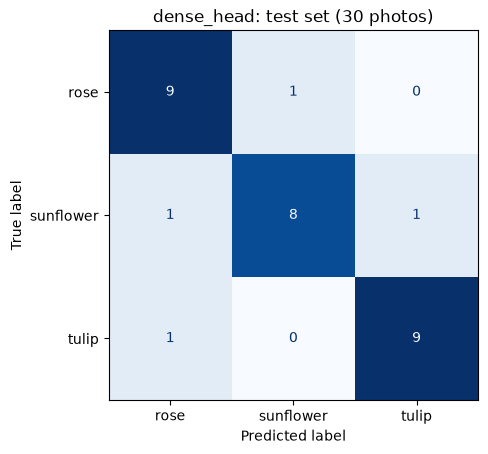

,photos,correct,accuracy,random baseline accuracy
rose,10,9,0.9,0.2
sunflower,10,8,0.8,0.3
tulip,10,9,0.9,0.5


In [31]:
y_best = test_pred[BEST].argmax(axis=1)
cm = confusion_matrix(y_test, y_best)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues", colorbar=False)
plt.title(f"{BEST}: test set (30 photos)")
plt.show()
pd.DataFrame({"photos": np.bincount(y_test),
              "correct": np.diag(cm),
              "accuracy": np.diag(cm) / np.bincount(y_test),
              "random baseline accuracy": [test_correct["random_baseline"][y_test == k].mean() for k in range(3)]},
             index=CLASSES).round(2)

**What we see:** the model makes 4 errors, one in each of four different cells: 1 rose taken for a
sunflower, 1 sunflower for a tulip, 1 sunflower for a rose and 1 tulip for a rose. Per class it gets 9 of 10 roses,
8 of 10 sunflowers and 9 of 10 tulips right (random guessing: 2, 3 and 5 of 10). With 10 photos per class, one photo is
10 points, so the differences between the classes are not meaningful. Our expectation from the validation set (5g), that
most errors would be tulips, is **not** confirmed: with so few photos, one or two hard photos decide.

### 6e. Every misclassified test photo

**What:** show every test photo that the chosen model gets wrong, with its true class, the prediction and its probability,
and save each one as a PNG in `abgabe/fehler/`.

**Decision:** we show the photo exactly as the model saw it (160 × 160, from the same loop as the label and the
prediction), not the original file, so that what we see is what the model got.

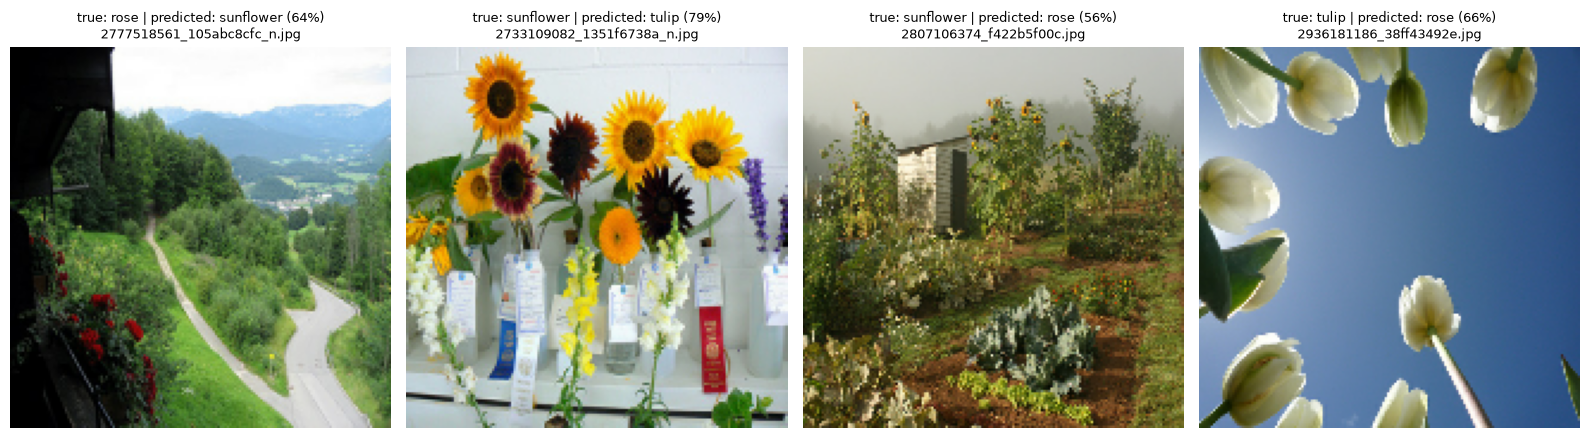

,p(rose),p(sunflower),p(tulip)
2777518561_105abc8cfc_n.jpg,0.331,0.640,0.029
2733109082_1351f6738a_n.jpg,0.009,0.197,0.794
2807106374_f422b5f00c.jpg,0.564,0.426,0.010
2936181186_38ff43492e.jpg,0.660,0.116,0.224


In [32]:
wrong = np.flatnonzero(y_best != y_test)
for f in (OUT / "fehler").glob("*.png"):
    f.unlink()  # remove error photos of an earlier run
fig, axes = plt.subplots(1, max(len(wrong), 1), figsize=(4 * max(len(wrong), 1), 4.4), squeeze=False)
for ax, i in zip(axes[0], wrong):
    probs = test_pred[BEST][i]
    title = (f"true: {CLASSES[y_test[i]]} | predicted: {CLASSES[y_best[i]]} ({probs.max():.0%})\n"
             f"{Path(test_ds.file_paths[i]).name}")
    ax.imshow(test_images[i].astype("uint8"))
    ax.set_title(title, fontsize=9)
    ax.axis("off")
    one, one_ax = plt.subplots(figsize=(4, 4.4))
    one_ax.imshow(test_images[i].astype("uint8"))
    one_ax.set_title(title, fontsize=9)
    one_ax.axis("off")
    one.savefig(OUT / "fehler" / f"{i:02d}_{CLASSES[y_test[i]]}_as_{CLASSES[y_best[i]]}.png", bbox_inches="tight")
    plt.close(one)
plt.tight_layout()
plt.show()
pd.DataFrame(test_pred[BEST][wrong], columns=[f"p({c})" for c in CLASSES],
             index=[Path(test_ds.file_paths[i]).name for i in wrong]).round(3)

**What we see:** four photos are wrong, with highest probabilities from **0.56 to 0.79**: the model is unsure
on all of them. What they have in common:
- In three of the four, **the flower is small in a wide scene**: a mountain landscape with a few red roses on a balcony
  (rose → sunflower, 64 %), a vegetable garden with sunflowers far behind a shed (sunflower → rose, 56 %), and a show
  table with many vases and other kinds of flowers (sunflower → tulip, 79 %).
- The fourth shows **white tulips from below** against a blue sky, an unusual view in a colour that roses also have
  (tulip → rose, 66 %).

This matches the validation errors (5g): the model fails when the flower is not the main subject of the photo or when the
view is unusual. Our explanation is a guess, not a proof: the frozen base describes the whole photo, so a small flower
has little weight in the 1280 numbers.

### 6f. The staff-check threshold on the test set

**What:** apply the threshold fixed in 5f to the test photos: how many photos would the model answer alone, how many of
those are right, and how many of the wrong answers would go to a member of staff? We also show the two neighbouring
thresholds as a **sensitivity check** (they were not chosen; they only show how much the result depends on this choice).

In [33]:
conf_test = test_pred[BEST].max(axis=1)
right = y_best == y_test
rows = []
for t in [round(THRESHOLD - 0.1, 2), THRESHOLD, round(min(THRESHOLD + 0.1, 0.99), 2)]:
    alone = conf_test >= t
    rows.append({"threshold": t, "chosen": t == THRESHOLD, "answered alone": int(alone.sum()),
                 "correct among those": int((right & alone).sum()), "sent to staff": int((~alone).sum()),
                 "errors caught by staff": int((~right & ~alone).sum()), "errors not caught": int((~right & alone).sum())})
pd.DataFrame(rows)

,threshold,chosen,answered alone,correct among those,sent to staff,errors caught by staff,errors not caught
0,0.85,False,14,14,16,4,0
1,0.95,True,9,9,21,4,0
2,0.99,False,3,3,27,4,0


**What we see:** with the threshold **0.95** fixed before the test, the model answers **9 of 30** test
photos alone, and all 9 are right; 21 photos go to staff, among them **all 4 errors**. At the neighbouring thresholds:
0.85 would answer 14 photos alone (all right), 0.99 only 3. On the test set every error had a probability below 0.80, so
0.85 would also have caught them all, but on the validation set 5 errors had 0.87 to 0.99. We keep the rule:
**staff check every answer below 0.95**. This saves staff work for about a third of the photos (35 % on the validation
set, 30 % on the test set). Even above 0.95, the validation set showed about 1 wrong answer in 10, so the garden centre
should keep a way for customers to report a wrong care guide.

### 6g. Is the validation accuracy a fair estimate? The expected accuracy on new photos

**What:** an honest number for the garden centre: the **test accuracy** of the chosen model (without any bonus) and a range
that contains the true accuracy on new photos of the same kind with high probability.

**How the range is built:**
1. the **Wilson interval** (95 %) for an accuracy measured on 30 photos. It is a standard interval for a share; unlike the
   simple "± 1.96 standard errors" it stays between 0 and 1 and works also when almost all photos are right;
2. widened by the **seed spread**: the standard deviation of the test accuracy over the three seeds, because a retrained
   model would have another seed. We add both parts like independent errors (square root of the sum of squares).

**Alternatives rejected:** the validation accuracy as the estimate (it chose the stopping epoch and the model, so it is a
little optimistic); an interval from the 30 test photos alone (it ignores that retraining changes the model).

In [34]:
def wilson(k, n, z=1.96):
    centre = (k + z**2 / 2) / (n + z**2)
    half = z * np.sqrt(k * (n - k) / n + z**2 / 4) / (n + z**2)
    return centre - half, centre + half


n_test = len(y_test)
k_test = int(test_correct[BEST].sum())
point = k_test / n_test
w_low, w_high = wilson(k_test, n_test)
seed_sd = spread.query("model == @BEST")["test"].std()
low_e = max(0.0, point - np.hypot(point - w_low, 1.96 * seed_sd))
high_e = min(1.0, point + np.hypot(w_high - point, 1.96 * seed_sd))
print(f"Chosen model {BEST}: validation {val_acc[BEST]:.3f}, test {point:.3f} ({k_test} of {n_test})")
print(f"Wilson 95 % interval: [{w_low:.3f}, {w_high:.3f}] | seed SD on test: {seed_sd:.3f}")
print(f"Expected accuracy on new photos of the same kind: {point:.3f}, range [{low_e:.3f}, {high_e:.3f}]")
BEGRUENDUNG = (f"Point = test accuracy of {BEST} on the {n_test} unseen test photos ({k_test} correct), range = "
               f"95 % Wilson interval for {n_test} photos widened by the seed spread of the test accuracy (SD {seed_sd:.3f}).")

Chosen model dense_head: validation 0.833, test 0.867 (26 of 30)
Wilson 95 % interval: [0.703, 0.947] | seed SD on test: 0.067
Expected accuracy on new photos of the same kind: 0.867, range [0.657, 1.000]


**What we see:** the chosen model gets 26 of 30 test photos right: point estimate **0.867**. The Wilson
interval for 30 photos goes from 0.703 to 0.947; the seed spread on the test set (standard deviation 0.067) widens it to
**0.657 to 1.000**. The validation accuracy (0.833) lies inside this range.

**Success criterion, as a classification on the test set:** the test accuracy (0.867) is also above 0.80, but the lower
end of the range (0.657) is below 0.80. So 30 test photos cannot prove that the model reaches 80 % on new photos; they
only show that it is very likely far better than guessing. In plain words: on new photos of the same kind, expect about
**87 of 100** right; it may be as low as about 66 or close to 100. Photos from customers may contain more wide scenes and
then be harder.

### 6h. Write `ergebnis.json`

**What:** save the main numbers in the format the client asked for. All numbers come from variables of this notebook.

In [35]:
result = {
    "metrik": "accuracy",
    "bildgroesse": list(IMAGE_SIZE),
    "bestes_modell": BEST,
    "tabelle": [{k: (None if pd.isna(v) else (int(v) if k.startswith("parameter") else v))
                 for k, v in row.items() if k != "chosen"} for row in table.to_dict("records")],
    "konfusion_test": cm.tolist(),
    "klassen": CLASSES,
    "erwartete_guete": {
        "accuracy": round(point, 4),
        "intervall": [round(low_e, 4), round(high_e, 4)],
        "begruendung": BEGRUENDUNG,
    },
}
(OUT / "ergebnis.json").write_text(json.dumps(result, indent=2, ensure_ascii=False))
print(json.dumps(result, indent=2, ensure_ascii=False))

{
  "metrik": "accuracy",
  "bildgroesse": [
    160,
    160
  ],
  "bestes_modell": "dense_head",
  "tabelle": [
    {
      "model": "random_baseline",
      "parameter_gesamt": null,
      "parameter_trainierbar": null,
      "val": 0.3833,
      "test": 0.3333
    },
    {
      "model": "dense_head",
      "parameter_gesamt": 2261827,
      "parameter_trainierbar": 3843,
      "val": 0.8333,
      "test": 0.8667
    },
    {
      "model": "dense_head_aug",
      "parameter_gesamt": 2261827,
      "parameter_trainierbar": 3843,
      "val": 0.85,
      "test": 0.8667
    }
  ],
  "konfusion_test": [
    [
      9,
      1,
      0
    ],
    [
      1,
      8,
      1
    ],
    [
      1,
      0,
      9
    ]
  ],
  "klassen": [
    "rose",
    "sunflower",
    "tulip"
  ],
  "erwartete_guete": {
    "accuracy": 0.8667,
    "intervall": [
      0.6574,
      1.0
    ],
    "begruendung": "Point = test accuracy of dense_head on the 30 unseen test photos (26 correct), range = 9

**What we see:** the file `abgabe/ergebnis.json` holds the table, the confusion matrix and the expected accuracy with its
range, in the requested format.

## Step 7. The model in the app (without a browser)

**What:** load the chosen model from `models/` with `keras.models.load_model`, read three test photos **from their files**
and prepare them exactly like `app.py` (`tf.io.decode_image` with 3 channels, then `tf.image.resize` to the input size of
the model). Then compare the probabilities with those from step 6.

**Decision:** we copy the three lines of `prepare_photo` from `app.py` instead of importing `app.py`; importing it would
start the Streamlit page code. We take the first photo of every class, plus nothing else, so the choice is fixed and not
picked by result.

**Alternative rejected:** starting the Streamlit server and uploading photos by hand. The task asks for a check without a
browser, and a check in code can be repeated by anyone.

In [36]:
app_model = keras.models.load_model(MODELS / f"{BEST}.keras")


def prepare_photo(photo_bytes, model):  # copied from app.py
    image = tf.io.decode_image(photo_bytes, channels=3, expand_animations=False)
    height, width = model.input_shape[1:3]
    return tf.image.resize(image, (height, width))


rows = []
for i in [int(np.flatnonzero(y_test == k)[0]) for k in range(3)]:
    path = test_ds.file_paths[i]
    pixels = prepare_photo(tf.io.read_file(path).numpy(), app_model)
    p_app = app_model.predict(pixels[np.newaxis], verbose=0)[0]
    rows.append({"photo": Path(path).name, "true": CLASSES[y_test[i]],
                 "app prediction": CLASSES[p_app.argmax()], "app probability": round(float(p_app.max()), 4),
                 "step 6 prediction": CLASSES[test_pred[BEST][i].argmax()],
                 "largest probability difference": float(np.abs(p_app - test_pred[BEST][i]).max())})
app_check = pd.DataFrame(rows)
app_check

E0000 00:00:1793357479.449393 1016036 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,photo,true,app prediction,app probability,step 6 prediction,largest probability difference
0,2607130050_9c34310004.jpg,rose,rose,0.7045,rose,5.364418e-07
1,2729206569_9dd2b5a3ed.jpg,sunflower,sunflower,0.8087,sunflower,1.490116e-08
2,2447151631_7551e6377b_n.jpg,tulip,tulip,0.7554,tulip,0.000000e+00


**What we see:** for the three test photos (the first rose, sunflower and tulip of the test folder), the
app's preparation gives the same prediction as step 6 (rose 0.70, sunflower 0.81, tulip 0.76), and the probabilities differ
by at most 0.0000005, a rounding difference. So the saved model works in `app.py` with raw photos: it contains its own
preprocessing and returns one probability per flower.

## When not to rely on the model

- **Other flowers or no flower** (daisy, lily, a cat): the model still answers rose, sunflower or tulip, sometimes with a
  high probability. The website must say clearly that only these three flowers are covered.
- **Wide scenes** in which the flower is small (parks, gardens, landscapes, shop displays): most errors on the validation
  and the test set are of this kind.
- **Yellow tulips**: on the validation set they were taken for sunflowers with probabilities up to 0.99; the staff-check
  threshold does **not** catch these.
- **Unusual views** (from below, extreme close-ups) and **several kinds of flowers** in one photo.
- **Very small photos** (shorter side far below 160 pixels): almost none in the training data.
- **After retraining:** another seed moved the test accuracy by up to 4 of 30 photos. A retrained model must be checked
  again on labelled photos before it replaces this one.

## Notes for the client (data)

- **No problems in the files:** 360 training and validation photos, all JPEG in RGB, all readable, no exact copies.
  The 30 test photos were checked at the test access (6b).
- **Near-copies inside the training set:** 6 training photos have a partner with similarity above 0.9 (4b). They do not
  harm the training, but a group that later builds its own cross-validation should keep such pairs in the same fold.
- **Small photos:** 5 of 360 photos have a shorter side below 160 pixels and are enlarged by the loading step.
- **Hard cases in the data:** yellow tulips in wide scenes (parks, flower beds) are rare in the training set and are the
  main source of confident errors (5g). More training photos of this kind would be the most useful addition.